<p style="text-align:center"><img src="images/08_web_gis.png" alt="Web and Cloud GIS" width="100%"></p>

# Web/Cloud GIS


Desktop GIS keeps data and computing on one machine. Web GIS puts maps and services on a
server that anyone can reach with a browser; cloud GIS moves the data and the computing
themselves into large shared infrastructure, where petabytes of imagery already live. This
notebook introduces the ideas that the rest of Module 08 builds on: how the pieces of a web
or cloud GIS fit together, which standards connect them, why "cloud-native" file formats
matter, how web maps are tiled, and where to find data. Every idea is tried out with GeoLattice
on real data.

Twelve notebooks take maps and analysis from one machine onto the web and into cloud data stores.

- **Web/Cloud GIS.** This notebook. Desktop, web and cloud GIS, the standards that connect them (WMS, WMTS, WFS, OGC API, STAC, TileJSON, XYZ), HTTP range requests, the tile pyramid, and finding imagery with `geolattice.rsense.get_images`.
- **Cloud-Native Rasters: COG, Zarr and STAC.** Sentinel-2 over Syracuse: check and write Cloud-Optimized GeoTIFFs, a multi-date Zarr cube, and a STAC catalogue whose footprints are stored as GeoParquet.
- **Cloud-Native Vectors: GeoParquet, FlatGeobuf and PMTiles.** Every union of Bangladesh as GeoParquet, FlatGeobuf, PMTiles, GeoPackage and GeoJSON Sequences, and how many bytes each format transfers over HTTP.
- **Spatial SQL: DuckDB, GeoPackage and PostGIS.** DuckDB on Bangladesh files, the same queries against a GeoPackage, and how those queries move to PostGIS.
- **Interactive Web Maps in Python: Folium, leafmap and lonboard.** Folium, leafmap and lonboard maps of Bangladesh poverty, rice-field arsenic, 37,923 soil samples and Syracuse NDVI, and what each map sends to the browser.
- **Serving Maps: Tiles and OGC APIs.** Raster tiles and an OGC API: Features service with `geolattice.web`, plus PMTiles shown in MapLibre, all on localhost.
- **Building Geospatial APIs with FastAPI.** A FastAPI service for Bangladesh: the union at a point, soil pH, and a district NDVI series, with API keys, rate limits and background jobs.
- **Web Apps for Geospatial Data: Streamlit, Panel and Solara.** The same Bangladesh district explorer in Streamlit, Panel and Solara, sharing one Python module for the data and the figures.
- **Scalable Processing: Dask, GPUs and Batch Jobs.** A Theil-Sen trend of monthly MODIS NDVI anomalies, 2000-2024, for every 1 km land pixel of Bangladesh, scaled with Dask, a GPU and batch jobs.
- **Cloud Platforms: Planetary Computer, Earth Engine and Copernicus openEO.** Planetary Computer, Earth Search and Copernicus catalogues beside Earth Engine and openEO, including a cloud-free NDVI composite and a haor-district summary.
- **DevOps for Geospatial Pipelines: Packaging, Testing, CI, Containers and Schedules.** The `haor_monitor` pipeline for Tanguar Haor: a package, tests, continuous integration, a container and a schedule.
- **Capstone: A Cloud Web-GIS for Flood Monitoring in the Haor Basin.** A flood web-GIS for the haor basin around Tanguar Haor and Sunamganj in 2024: Sentinel-1 water maps, statistics by union, tiles, an API and a web map.

Library: `geolattice.web`, with imagery search in `geolattice.rsense`.



### Learning objectives

1. Distinguish desktop, web and cloud GIS, and describe the layers of a cloud GIS system.
2. Name the main OGC and community standards (WMS, WMTS, WFS, OGC API, STAC, TileJSON, XYZ).
3. Explain HTTP range requests and measure how little data a cloud-native read transfers.
4. Work with the XYZ tile pyramid used by every web map.
5. Search imagery catalogues with `geolattice.rsense.get_images` and inspect what is available.
6. Weigh cost, egress, licensing and data-location questions when choosing where to compute.



### Data

| Data | Source |
|---|---|
| New York county boundaries | `Data/00_shared/vector_data/USA/NY_County_GCS.shp` |
| Sentinel-2 L2A band 4 (red), tile 18TUN, 2 August 2025 | Read remotely from the public AWS bucket `sentinel-cogs` |
| Sentinel-2, Landsat and NAIP scene lists | Searched with `geolattice.rsense.get_images.search_images` (Earth Search on AWS) |



### Contents

- [What this folder covers](#what-this-folder-covers)
1. Desktop, web and cloud GIS
2. The layers of a cloud GIS
3. Standards that connect the pieces
4. Setup
5. Cloud-native reading: HTTP range requests
6. The XYZ tile pyramid
7. Finding data: catalogues and `get_images`
8. A web service in a few lines
9. Cost, egress, licensing and location
10. Module roadmap, summary and exercises

## Desktop, web and cloud GIS

| | Desktop GIS | Web GIS | Cloud GIS |
|---|---|---|---|
| Where data live | Local disk or a file server | A server database or file store | Object storage (S3, Google Cloud Storage, Azure Blob) shared by many users |
| Where computing happens | The user's computer | The server (rendering, queries) | Elastic clusters, GPUs and serverless functions, next to the data |
| How users reach it | Installed software (QGIS, ArcGIS Pro) | A browser or a mobile app | Notebooks, APIs and browsers |
| Scale | One user, one machine | Many users, modest data | Many users, petabytes |
| Typical Python tools | GeoPandas, rasterio, GeoLattice | Folium, leafmap, Streamlit, FastAPI | Dask, STAC, Zarr, Planetary Computer, Earth Engine |

The shift from desktop to cloud is driven by data volume. The Landsat and Sentinel archives
are several petabytes and grow by terabytes a day. Downloading them is impractical, so the
modern pattern is the reverse: **bring the code to the data**, read only the pixels needed,
and send results (maps, tables, tiles) to users.

## The layers of a cloud GIS

| Layer | Role | Examples | In GeoLattice |
|---|---|---|---|
| **Storage** | Keep files cheaply and durably, served over HTTP | Amazon S3, Google Cloud Storage, Azure Blob, on-premise MinIO | `geolattice.web.to_vsi_path`, `cloud_env` |
| **Formats** | Arrange files so parts can be read without downloading everything | COG, Zarr, GeoParquet, FlatGeobuf, PMTiles, COPC | `to_cog`, `validate_cog`, `write_geoparquet`, `write_pmtiles`, `rs.scale.to_zarr_cube` |
| **Catalogue** | Describe what exists, where and when | STAC APIs (Earth Search, Planetary Computer), CMR, CDSE OData | `rs.access.stac_search`, `rs.get_images.search_images`, `rs.scale.export_stac` |
| **Compute** | Process data at scale, near the storage | Dask clusters, Kubernetes, serverless functions, Earth Engine | `rs.scale.start_cluster`, `rs.apply_tiled`, CPU/GPU backend |
| **Serving** | Deliver maps and data to clients | Tile servers (TiTiler), OGC API servers (pygeoapi), GeoServer | `geolattice.web.create_app`, `render_tile`, `make_xyz_tiles` |
| **Client** | Show and interact | Leaflet, MapLibre, OpenLayers, QGIS, notebooks, Streamlit | `geolattice.viz.interactive_map`, `geolattice.web.leaflet_html` |

Notebooks 08_01-08_10 follow these layers from bottom to top; the capstone (08_11) joins them.

## Standards that connect the pieces

Standards let any client talk to any server. The Open Geospatial Consortium (OGC) defines most
of them; STAC and the tile conventions come from the community.

| Standard | What it serves | Style |
|---|---|---|
| **WMS** (Web Map Service) | Rendered map images for a bounding box | Classic OGC, XML capabilities |
| **WMTS** (Web Map Tile Service) | Pre-cut map tiles | Classic OGC |
| **WFS** (Web Feature Service) | Vector features | Classic OGC, GML |
| **WCS** (Web Coverage Service) | Raster data values | Classic OGC |
| **OGC API: Features / Tiles / Maps / Processes** | The modern successors: features, tiles, maps, processing | REST + JSON, OpenAPI |
| **XYZ / TMS tiles** | 256 × 256 images addressed by zoom, column and row | Community convention |
| **TileJSON** | Metadata for a tile layer (URL template, bounds, zooms) | Community (Mapbox) |
| **STAC** (SpatioTemporal Asset Catalog) | Catalogues of imagery and other assets | Community, JSON, now an OGC Community Standard |
| **GeoJSON** | Features in JSON | IETF RFC 7946 |

The rule of thumb today: **OGC API + GeoJSON for vector services, XYZ tiles + TileJSON for
maps, STAC for catalogues, COG / Zarr / GeoParquet for files.**

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: imports, plot defaults, and the New York county AOI used throughout
%matplotlib inline
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import geolattice
import geolattice.web as web
from geolattice.rsense.get_images import bands_for, list_collections, search_images

# Load NY counties and keep Onondaga as the working study area
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
DATA = Path("../../../Data")
counties = gpd.read_file(DATA / "00_shared" / "vector_data" / "USA" / "NY_County_GCS.shp")
onondaga = counties[counties["COUNTY"] == "Onondaga County"]
SYRACUSE = (-76.25, 43.00, -76.10, 43.10)                 # lon/lat box around the city
print("geolattice", geolattice.__version__, "| counties:", len(counties), "| Onondaga bounds:",
      tuple(round(v, 3) for v in onondaga.total_bounds))


geolattice 0.3.35 | counties: 83 | Onondaga bounds: (np.float64(-76.5), np.float64(42.771), np.float64(-75.895), np.float64(43.272))


## Cloud-native reading: HTTP range requests

A web server normally sends a whole file. With an HTTP **range request** (`Range: bytes=a-b`)
the client asks for only part of it, and the server answers `206 Partial Content`. Cloud
object stores all support this. A file is **cloud-native** when its layout lets a client find
the bytes it needs from a small header: a Cloud-Optimized GeoTIFF stores its headers first and
its pixels in independent tiles, so reading one area costs a few small requests.

First we ask the server about one Sentinel-2 band on AWS:

In [2]:
# Inspect a public Sentinel-2 COG URL without downloading the whole file
COG_URL = ("https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/"
           "18/T/UN/2025/8/S2C_18TUN_20250802_0_L2A/B04.tif")
info = web.remote_info(COG_URL)
pd.Series(info).to_frame("value")


,value
url,https://sentinel-cogs.s3.us-west-2.amazonaws.c...
status,206
size,91274825
content_type,image/tiff; application=geotiff; profile=cloud...
range_requests,True
etag,"""c5c60cdc492a1263fcb5fba3ea6846c1-11"""
error,None


Now we read pixels with GDAL, which records how many bytes it downloads. We read twice:
a 512 × 512 window over Syracuse at full resolution (10 m), and the whole 110 × 110 km tile
from its smallest overview.

In [3]:
# Compare bytes transferred for a local window vs a low-resolution overview
from osgeo import gdal
from pyproj import Transformer
gdal.UseExceptions()

def network_bytes():
    # Pull GDAL HTTP GET totals since the last NetworkStatsReset
    stats = json.loads(gdal.NetworkStatsGetAsSerializedJSON() or "{}")
    return stats.get("methods", {}).get("GET", {}).get("downloaded_bytes", 0), \
        stats.get("methods", {}).get("GET", {}).get("count", 0)

rows = []
with web.cloud_env(anonymous=True, CPL_VSIL_NETWORK_STATS_ENABLED="YES"):
    # Full-resolution 512x512 window centered near Syracuse
    gdal.NetworkStatsReset()
    ds = gdal.Open(web.to_vsi_path(COG_URL))
    band = ds.GetRasterBand(1)
    gt = ds.GetGeoTransform()
    x, y = Transformer.from_crs(4326, ds.GetSpatialRef().ExportToWkt(), always_xy=True).transform(-76.15, 43.05)
    col, row = int((x - gt[0]) / gt[1]) - 256, int((y - gt[3]) / gt[5]) - 256
    t0 = time.perf_counter()
    window = band.ReadAsArray(col, row, 512, 512)
    got, calls = network_bytes()
    rows.append({"read": "512 × 512 window over Syracuse (10 m)", "pixels": window.size,
                 "bytes downloaded": got, "GET requests": calls, "seconds": round(time.perf_counter() - t0, 2)})

    # Whole tile from the coarsest overview (much fewer bytes)
    gdal.NetworkStatsReset()
    ovr = band.GetOverview(band.GetOverviewCount() - 1)
    t0 = time.perf_counter()
    overview = ovr.ReadAsArray()
    got, calls = network_bytes()
    rows.append({"read": f"whole tile from the smallest overview ({ovr.XSize} × {ovr.YSize})", "pixels": overview.size,
                 "bytes downloaded": got, "GET requests": calls, "seconds": round(time.perf_counter() - t0, 2)})
    full_size = ds.RasterXSize, ds.RasterYSize
    ds = None

reads = pd.DataFrame(rows).set_index("read")
reads["% of file"] = (reads["bytes downloaded"] / info["size"] * 100).round(2)
print(f"File: {info['size'] / 1e6:.1f} MB, {full_size[0]:,} × {full_size[1]:,} pixels")
reads


File: 91.3 MB, 10,980 × 10,980 pixels


,pixels,bytes downloaded,GET requests,seconds,% of file
read,,,,,
512 × 512 window over Syracuse (10 m),262144,2246026,2,4.51,2.46
whole tile from the smallest overview (687 × 687),471969,294912,1,0.76,0.32


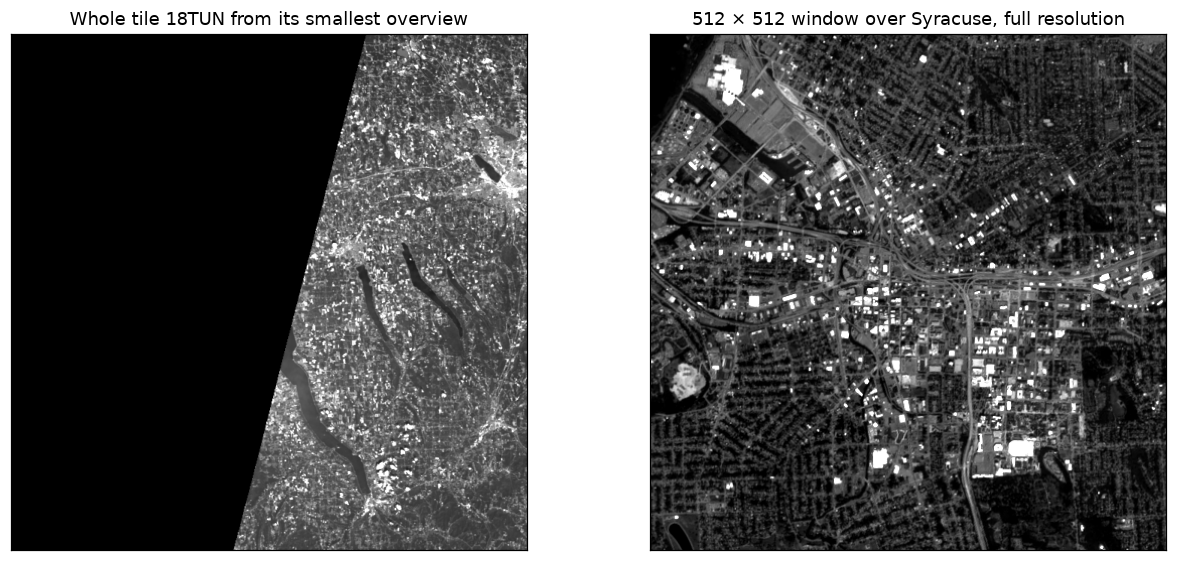

In [4]:
# Side-by-side: coarse overview of the tile vs the full-res Syracuse window
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
axes[0].imshow(overview, cmap="gray", vmin=0, vmax=np.percentile(overview[overview > 0], 98))
axes[0].set_title("Whole tile 18TUN from its smallest overview")
axes[1].imshow(window, cmap="gray", vmin=np.percentile(window, 2), vmax=np.percentile(window, 98))
axes[1].set_title("512 × 512 window over Syracuse, full resolution")
for a in axes:
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
plt.tight_layout(); plt.show()


The red band is a 91 MB file of 10,980 × 10,980 pixels, and the server answers range requests
(status 206). Reading a 512 × 512 window over Syracuse transferred about 2.2 MB in two
requests, 2.5% of the file. Reading the whole 110 × 110 km tile at its smallest overview
transferred 0.29 MB, 0.3%.

The window cost more than its 0.5 MB of pixels because this COG is cut into 1,024 × 1,024
blocks: GDAL must fetch every block the window touches, here up to four. Block size is a design
choice that Notebook 08_01 explores.

The overview image shows why overviews exist: a zoomed-out view of a whole Sentinel-2 tile needs
only one small request. The black wedge on its left lies outside this orbit's 290 km imaging
swath. Timings (one to several seconds here) depend mostly on network latency, not on the
number of bytes, which is why cloud-native reads try to need **few** requests.

## The XYZ tile pyramid

Web maps cut the world into 256 × 256-pixel tiles in the Web Mercator projection. At zoom 0 one
tile covers the world; each zoom level doubles the number of tiles in each direction. A tile is
addressed by its zoom, column and row: `{z}/{x}/{y}`. `geolattice.web` implements the tile
arithmetic.

In [5]:
# Build a Web Mercator zoom pyramid table for Syracuse / Onondaga
lat = 43.05
rows = []
for z in [0, 2, 5, 8, 10, 12, 14, 16, 18]:
    t = web.lonlat_to_tile(-76.15, lat, z)
    rows.append({"zoom": z, "tiles in the world": f"{4 ** z:,}",
                 "pixel size at equator (m)": round(web.tile_resolution(z), 2),
                 f"pixel size at {lat}°N (m)": round(web.tile_resolution(z, latitude=lat), 2),
                 "tile containing Syracuse": f"{t.z}/{t.x}/{t.y}",
                 "tiles covering Onondaga County": len(list(web.tiles_for_bounds(*onondaga.total_bounds, zooms=z)))})
pyramid = pd.DataFrame(rows).set_index("zoom")
pyramid


,tiles in the world,pixel size at equator (m),pixel size at 43.05°N (m),tile containing Syracuse,tiles covering Onondaga County
zoom,,,,,
0,1,156543.03,114395.12,0/0/0,1
2,16,39135.76,28598.78,2/1/1,1
5,"1,024",4891.97,3574.85,5/9/11,1
8,"65,536",611.50,446.86,8/73/94,4
10,"1,048,576",152.87,111.71,10/295/376,9
12,"16,777,216",38.22,27.93,12/1181/1504,72
14,"268,435,456",9.55,6.98,14/4726/6017,896
16,"4,294,967,296",2.39,1.75,16/18905/24068,13986
18,"68,719,476,736",0.60,0.44,18/75621/96274,220941


Zoom whose pixels match each sensor at Syracuse:
  MODIS 250 m      → zoom 9
  Landsat 30 m     → zoom 12
  Sentinel-2 10 m  → zoom 14
  PlanetScope 3 m  → zoom 16
  NAIP 0.6 m       → zoom 18


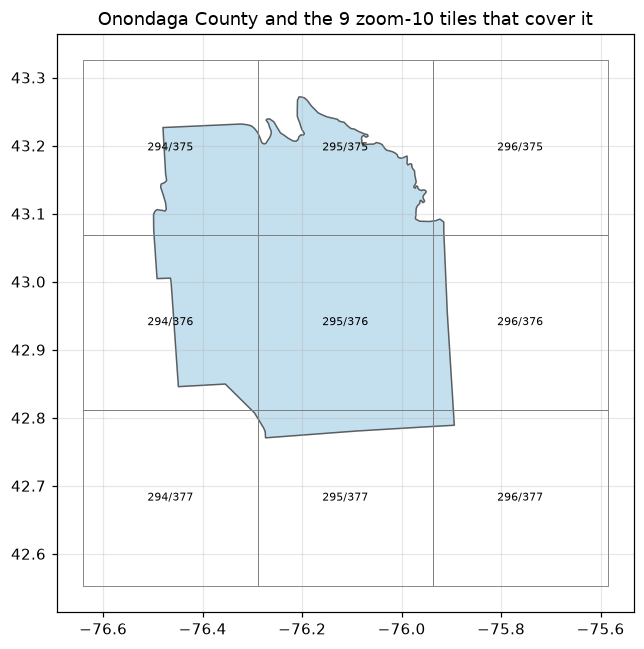

In [6]:
# Match common sensor resolutions to zoom levels, then map Onondaga tiles at z=10
print("Zoom whose pixels match each sensor at Syracuse:")
for sensor, res in [("MODIS 250 m", 250), ("Landsat 30 m", 30), ("Sentinel-2 10 m", 10),
                    ("PlanetScope 3 m", 3), ("NAIP 0.6 m", 0.6)]:
    print(f"  {sensor:16s} → zoom {web.zoom_for_resolution(res, latitude=lat)}")
# Draw the zoom-10 tile grid over Onondaga County
z = 10
tiles = list(web.tiles_for_bounds(*onondaga.total_bounds, zooms=z))
grid = gpd.GeoDataFrame({"tile": [f"{t.z}/{t.x}/{t.y}" for t in tiles]},
                        geometry=[__import__("shapely.geometry", fromlist=["box"]).box(*web.tile_bounds(*t)) for t in tiles],
                        crs=4326)
ax = grid.boundary.plot(color="grey", lw=0.6, figsize=(6.5, 6))
onondaga.plot(ax=ax, color="#9ecae1", alpha=0.6, edgecolor="k")
for _, r in grid.iterrows():
    c = r.geometry.centroid
    ax.annotate(r.tile.split("/", 1)[1], (c.x, c.y), ha="center", va="center", fontsize=7)
ax.set_title(f"Onondaga County and the {len(tiles)} zoom-{z} tiles that cover it")
plt.tight_layout(); plt.show()


Each zoom level halves the pixel size. At Syracuse's latitude, map pixels match Landsat's 30 m
at zoom 12, Sentinel-2's 10 m at zoom 14 and NAIP's 0.6 m at zoom 18. Those are the deepest
zooms worth rendering for each dataset; beyond them a tile server only enlarges pixels.

The number of tiles grows fourfold per level: Onondaga County fits in 9 tiles at zoom 10, 72 at
zoom 12 and 896 at zoom 14. This growth is why tile servers render on demand and cache, rather
than pre-rendering every level for large areas (Notebook 08_05).

## Finding data: catalogues and `get_images`

Cloud imagery is found through **catalogues**. `geolattice.rsense.get_images` gives one interface to
five of them, the same ones the [PyGIS Explorer app](https://zia207-pygis-explorer-app-ou8ehd.streamlit.app/)
uses:

* `search_images(...)` lists scenes for an area and dates and downloads nothing;
* `get_images(out, ...)` searches and writes the selected scenes (clipped to the area, or whole)
  into a folder, with an `aoi.geojson` and a `request.json` recording the request.

Note that `geolattice.rsense.get_images` is a module; import the functions from it.

In [7]:
# List STAC sources available through geolattice and show example band names
catalogue = pd.DataFrame([{"source": s, "collections": len(c), "examples": ", ".join(c[:4]) + (" …" if len(c) > 4 else "")}
                          for s, c in list_collections().items()]).set_index("source")
display(catalogue)
print("Sentinel-2 L2A bands:", ", ".join(bands_for("sentinel-2-l2a")))
print("Landsat C2 L2 bands: ", ", ".join(bands_for("landsat-c2-l2")))


,collections,examples
source,,
earth-search,4,"sentinel-2-l2a, sentinel-2-l1c, landsat-c2-l2,..."
planetary,20,"sentinel-2-l2a, sentinel-1-rtc, sentinel-1-grd..."
cdse,6,"SENTINEL-2, SENTINEL-1, SENTINEL-3, SENTINEL-5P …"
rcm-ard,1,rcm-ard
noaa,5,"noaa-rgb8, noaa-rgb16, noaa-rgbn8, noaa-cir8 …"
usgs,2,"lidar-lpc, lidar-projects"


Sentinel-2 L2A bands: blue, green, red, nir, rededge1, rededge2, rededge3, nir08, swir16, swir22, scl, coastal, visual
Landsat C2 L2 bands:  blue, green, red, nir, swir16, swir22, coastal, lwir11, qa_pixel


Searches accept a bounding box or any area: a vector file, a GeoDataFrame or a shapely geometry.
Here the area is the Onondaga County polygon, and we look for Sentinel-2 and Landsat scenes in
the 2025 growing season and the latest NAIP aerial photography.

In [8]:
# Search STAC for Sentinel-2, Landsat, and NAIP scenes over Onondaga
season = ("2025-05-01", "2025-09-30")
s2 = search_images(aoi=onondaga, dates=season, source="earth-search", collection="sentinel-2-l2a", limit=1000)
ls = search_images(aoi=onondaga, dates=season, source="earth-search", collection="landsat-c2-l2", limit=1000)
naip = search_images(aoi=onondaga, source="earth-search", collection="naip", limit=50)

# Normalize search results into a dated DataFrame
def scene_table(found):
    df = pd.DataFrame(found.scenes)
    if df.empty:
        return df
    df["date"] = pd.to_datetime(df["datetime"]).dt.date
    return df

s2_df, ls_df, naip_df = scene_table(s2), scene_table(ls), scene_table(naip)
summary = pd.DataFrame({
    "scenes": [len(s2_df), len(ls_df), len(naip_df)],
    "distinct dates": [s2_df["date"].nunique(), ls_df["date"].nunique(), naip_df["date"].nunique() if len(naip_df) else 0],
    "scenes ≤ 10 % cloud": [int((s2_df["cloud"] <= 10).sum()), int((ls_df["cloud"] <= 10).sum()), np.nan],
}, index=["Sentinel-2 L2A, May-Sep 2025", "Landsat 8/9 C2 L2, May-Sep 2025", "NAIP (latest)"])
summary


302 scene(s) from earth-search / sentinel-2-l2a
38 scene(s) from earth-search / landsat-c2-l2
33 scene(s) from earth-search / naip


,scenes,distinct dates,scenes ≤ 10 % cloud
"Sentinel-2 L2A, May-Sep 2025",302,67,56.0
"Landsat 8/9 C2 L2, May-Sep 2025",38,38,8.0
NAIP (latest),33,6,NaN


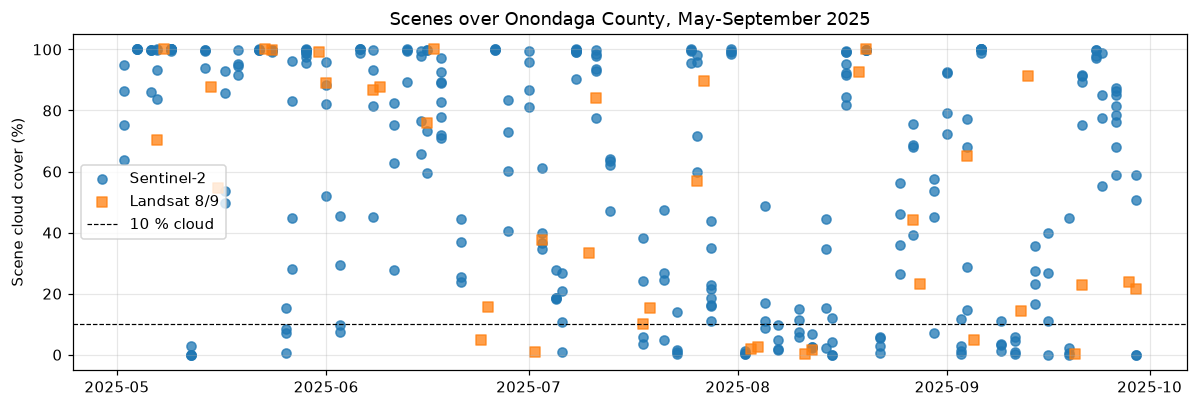

NAIP: 33 quarter-quad images, acquired 2022-07-09 to 2022-11-08


,id,date
0,ny_m_4207509_sw_18_060_20221108,2022-11-08
1,ny_m_4207501_sw_18_060_20221108,2022-11-08
2,ny_m_4207501_nw_18_060_20221108,2022-11-08


In [9]:
# Plot cloud cover over the season; peek at a few NAIP acquisitions
fig, ax = plt.subplots(figsize=(11, 3.8))
for df, name, mk in [(s2_df, "Sentinel-2", "o"), (ls_df, "Landsat 8/9", "s")]:
    ax.scatter(pd.to_datetime(df["date"]), df["cloud"], marker=mk, label=name, alpha=0.75)
ax.axhline(10, color="k", ls="--", lw=0.8, label="10 % cloud")
ax.set_ylabel("Scene cloud cover (%)"); ax.set_title("Scenes over Onondaga County, May-September 2025")
ax.legend(); plt.tight_layout(); plt.show()
if len(naip_df):
    print(f"NAIP: {len(naip_df)} quarter-quad images, acquired {naip_df['date'].min()} to {naip_df['date'].max()}")
    display(naip_df[["id", "date"]].head(3))


For May-September 2025, Earth Search lists 302 Sentinel-2 L2A scenes over Onondaga County on 67
dates. The county is covered by several 110 km tiles and two orbits, so most dates have several
scenes; 56 scenes were at most 10% cloudy. Landsat 8 and 9 give 38 scenes on 38 dates, 8 of them
at most 10% cloudy. The latest NAIP aerial survey (33 quarter-quadrangle images) was flown
between July and November 2022.

The plot shows the usual pattern for a humid region: most scenes are cloudy, and clear ones
come in spells, here mainly August and September. Sentinel-2's denser revisits are what make
cloud-free monitoring possible. All of this took a few seconds and downloaded only metadata.

## A web service in a few lines

A web GIS answers HTTP requests with JSON, images or HTML. `geolattice.web.create_app` builds a
small server for vector layers (OGC API: Features) and rasters (XYZ tiles). We start one for
the New York counties and talk to it the way a browser would, with Starlette's test client
(Notebook 08_05 runs it as a real server).

In [10]:
# Spin up an in-process OGC API Features app and query counties near Syracuse
from starlette.testclient import TestClient

app = web.create_app(vectors={"ny_counties": counties}, title="New York counties")
client = TestClient(app)
landing = client.get("/").json()
print("Landing page links:", [l["rel"] for l in landing["links"]])
collection = client.get("/collections/ny_counties").json()
print("Collection extent:", [round(v, 3) for v in collection["extent"]["spatial"]["bbox"][0]])
r = client.get("/collections/ny_counties/items", params={"bbox": ",".join(map(str, SYRACUSE)), "limit": 10})
fc = r.json()
print(f"GET {r.url}\n→ {r.status_code} {r.headers['content-type']}: "
      f"{fc['numberMatched']} feature(s): {[f['properties']['COUNTY'] for f in fc['features']]}")


Landing page links: ['self', 'service-desc', 'conformance', 'data', 'tiles', 'alternate']
Collection extent: [-79.763, 40.499, -71.856, 45.011]
GET http://testserver/collections/ny_counties/items?bbox=-76.25%2C43.0%2C-76.1%2C43.1&limit=10
→ 200 application/geo+json: 1 feature(s): ['Onondaga County']


The same three requests work from any language or tool: a browser, `curl`, QGIS (which reads
OGC API: Features directly), or JavaScript in a web page.



## Cost, egress, licensing and location

| Question | Why it matters |
|---|---|
| **Egress** | Cloud providers charge for data leaving their network (often around $0.05-0.09 per GB), not for reading inside the same region. Computing in the region where the data live (us-west-2 for Earth Search's Sentinel-2) is cheaper and faster. |
| **Requester pays** | Some buckets (USGS Landsat on S3) bill the reader; `cloud_env(requester_pays=True)` acknowledges this. |
| **Storage class and format** | Cloud-native formats cut both transfer and compute; compressed COG and GeoParquet are often a third of the size of plain files. |
| **Compute model** | Always-on servers suit steady traffic; serverless functions suit bursts; clusters suit big batch jobs. |
| **Licensing** | Open data (Landsat, Copernicus) may be redistributed; commercial imagery usually may not be served publicly. |
| **Data location (sovereignty)** | Health, personal or government data may have to stay in a country or on premises; object storage like MinIO gives cloud-style access on local hardware. |
| **Lock-in** | Open formats (COG, Zarr, GeoParquet) and open standards (STAC, OGC API) keep data and code portable between providers. |

## Module roadmap, summary and exercises

| Notebook | Topic |
|---|---|
| 08_01 | Cloud-native rasters: COG, Zarr and STAC |
| 08_02 | Cloud-native vectors: GeoParquet, FlatGeobuf, PMTiles |
| 08_03 | Spatial SQL with DuckDB and PostGIS |
| 08_04 | Interactive web maps |
| 08_05 | Serving maps: tiles and OGC APIs |
| 08_06 | Geospatial APIs |
| 08_07 | Web apps |
| 08_08 | Scalable processing |
| 08_09 | Cloud platforms |
| 08_10 | DevOps for geospatial |
| 08_11 | Capstone |

**Key ideas**

- Cloud GIS brings computing to the data; web GIS brings results to users.
- Open standards (OGC API, STAC, XYZ tiles, GeoJSON) let any client use any server.
- Cloud-native formats plus HTTP range requests let a program read a small part of a large
  remote file.
- Every web map is a pyramid of 256 × 256 tiles addressed by `{z}/{x}/{y}`.
- Catalogues tell you what exists before you download anything; `get_images` searches five of them.

**What we measured**

- Reading a 512 × 512 window from a 91 MB remote Sentinel-2 band transferred about 2.2 MB (2.5%);
  an overview of the whole tile transferred 0.29 MB.
- Onondaga County needs 9 tiles at zoom 10 and 896 at zoom 14; Sentinel-2's 10 m pixels match
  zoom 14 at this latitude.
- One search found 302 Sentinel-2 and 38 Landsat scenes for the 2025 season, and the latest NAIP
  (2022), without downloading any imagery.

**Exercises**

1. Repeat Section 5 with a 2048 × 2048 window. How do the bytes downloaded and the number of
   requests scale with the window size?
2. Compute how many zoom-14 tiles cover New York State and how much storage they would need at
   about 20 KB per tile.
3. Search `source="planetary"` for `"sentinel-1-rtc"` over Onondaga County in the same season.
   How does the number of dates compare with Sentinel-2, and why?
4. Request `/collections/ny_counties/items?COUNTY=Onondaga County` from the test client and
   explain how attribute filters map to the URL.
5. List three datasets you work with and decide, for each, whether it should live in object
   storage, a database or on a local disk.

**References**

- Open Geospatial Consortium. OGC API, Features, Part 1: Core (17-069r4), and the OGC API family. https://ogcapi.ogc.org
- STAC specification. https://stacspec.org
- Cloud-Optimized GeoTIFF. https://cogeo.org
- Cloud-Native Geospatial Foundation. *Cloud-Optimized Geospatial Formats Guide*. https://guide.cloudnativegeo.org
- Abernathey, R. et al. (2021). Cloud-native repositories for big scientific data. *Computing in Science & Engineering* 23(2), 26-35.